In [7]:
## Plot the curve 
import matplotlib.pyplot as plt
import numpy as np
# SETUP 
import seaborn as sns 
plt.style.use('seaborn-v0_8-paper')

import os
os.environ["PATH"] += os.pathsep + os.path.expanduser("/home/runai-home/texlive/bin/x86_64-linux")

#plt.rc('font', family='Avenir', serif='Computer Modern')
text_size = 22
plt.rc('text', usetex=True)
plt.rc('xtick', labelsize=text_size)
plt.rc('ytick', labelsize=text_size)
plt.rc('axes', labelsize=text_size)
plt.rc('axes', titlesize=text_size)
plt.rc('legend',fontsize=18) # using a size in points
plt.rcParams['axes.linewidth'] = 1.15
plt.rcParams["figure.figsize"] = (6.,4.1631189606246317)
#plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"

rc = {"axes.spines.left" : True,
      "axes.spines.right" : True,
      "axes.spines.bottom" : True,
      "axes.spines.top" : True,
      "xtick.bottom" : True,
      "xtick.labelbottom" : True,
      "ytick.labelleft" : True,
      "ytick.left" : True
     }

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    #"font.sans-serif": ["Helvetica"]}
    "pgf.texsystem": "pdflatex",
    "pgf.preamble": r"\usepackage{bm}",
    "font.family": "serif",
    # Use LaTeX default serif font.
    "font.serif": ["Times"],
    # Use specific cursive fonts.
    "font.cursive": ["Comic Neue", "Comic Sans MS"],

})

plt.rcParams.update(rc)

In [8]:
# import matplotlib.pyplot as plt
# print(plt.style.available)

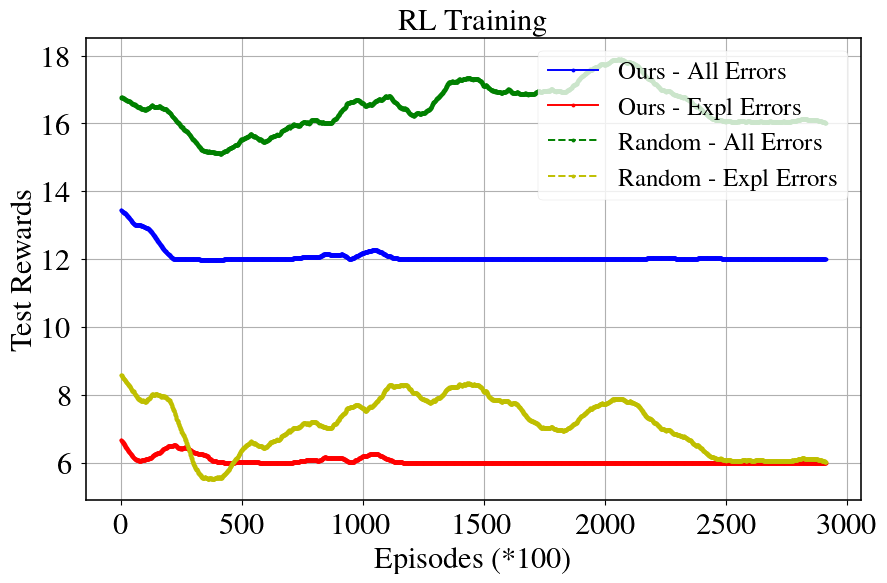

In [9]:
import pickle
import matplotlib.pyplot as plt

with open('../vu2/RL4Auditing/tabular/expl_diversity_statistics_20steps.pkl', 'rb') as file:
    data = pickle.load(file)
# Extract every 1000th element
selected_elements = data["test_reward"]
selected_elements_expl = data["test_reward_expl"]


with open('../vu2/RL4Auditing/tabular/expl_diversity_statistics_30steps.pkl', 'rb') as file:
    data = pickle.load(file)
# Extract every 1000th element
random_selected_elements = data["test_reward"]
random_selected_elements_expl = data["test_reward_expl"]


window_size = 100
averages = []
averages_explain = []

random_averages = []
random_averages_explain = []

# Ensure the list is large enough
if len(random_selected_elements) >= window_size:
    for i in range(window_size, len(random_selected_elements) + 1):
        # Get the last 100 elements ending at index i
        window = selected_elements[i - window_size:i]
        average = sum(window) / window_size
        averages.append(average)
        
        window2 = selected_elements_expl[i - window_size:i]
        average2 = sum(window2) / window_size
        
        averages_explain.append(average2)

        window = random_selected_elements[i - window_size:i]
        average = sum(window) / window_size
        random_averages.append(average)
        
        window2 = random_selected_elements_expl[i - window_size:i]
        average2 = sum(window2) / window_size
        
        random_averages_explain.append(average2)
# Create corresponding x-axis values (iterations)
iterations = list(range(len(random_averages_explain)))

# Plot the selected elements
plt.figure(figsize=(10, 6))
plt.plot(iterations, averages, marker='.', linestyle='-', color='b', label='Ours - All Errors')
plt.plot(iterations, averages_explain, marker='.', linestyle='-', color='r', label='Ours - Expl Errors')
plt.plot(iterations, random_averages, marker='.', linestyle='--', color='g', label='Random - All Errors')
plt.plot(iterations, random_averages_explain, marker='.', linestyle='--', color='y', label='Random - Expl Errors')
plt.xlabel('Episodes')
plt.ylabel('Test Rewards')
plt.title('RL Training')
plt.legend()
plt.grid()
plt.show()